# Milestone 1 — Audio basics + stem separation with Demucs

Goal of this notebook:
1. Understand what digital audio *is* (samples, sample rate, channels).
2. Move from the time domain to the frequency domain (FFT → STFT → spectrogram).
3. Try a classic, non-ML separation trick (harmonic/percussive masking) to build intuition.
4. Run a pretrained **Demucs v4** model to split a song into stems.
5. (Optional) Measure separation quality with **SDR** on MUSDB18 sample tracks.

**Before running:** put any song at `audio/song.mp3` (relative to the project root).

In [39]:
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
from IPython.display import Audio, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SONG = ROOT / "audio" / "song.mp3"
STEMS_DIR = ROOT / "stems"

# Only analyse/separate a slice of the song to keep things fast while learning.
OFFSET_S = 30.0    # start 30 s into the song
DURATION_S = 30.0  # set to None for the whole song

assert SONG.exists(), f"Put a song at {SONG} first"

if torch.backends.mps.is_available():
    DEVICE = "mps"   # Apple Silicon GPU
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.1 | device: mps


## 1. What is digital audio?

Sound is air pressure changing over time. A microphone turns that into a voltage, and an
analog-to-digital converter **samples** it at a fixed rate.

- **Sample rate (sr):** samples per second. CD quality is 44,100 Hz. By the Nyquist theorem,
  this can represent frequencies up to sr/2 = 22,050 Hz (about the limit of human hearing).
- **Channels:** 1 = mono, 2 = stereo (left/right).
- **Sample values:** after loading, floats in [-1, 1].

So a 3-minute stereo song at 44.1 kHz is just a `(2, 7_938_000)` array of numbers.

In [41]:
# mono=False keeps stereo; sr=None keeps the file's native sample rate.
y, sr = librosa.load(SONG, sr=None, mono=False, offset=OFFSET_S, duration=DURATION_S)
if y.ndim == 1:  # mono file -> make it (1, n)
    y = y[None, :]

print("shape (channels, samples):", y.shape)
print("sample rate:", sr, "Hz")
print("duration:", y.shape[1] / sr, "s")
print("min/max sample:", y.min(), y.max())
display(Audio(y, rate=sr))

[src/libmpg123/parse.c:skip_junk():1260] error: Giving up searching valid MPEG header after 65536 bytes of junk.


LibsndfileError: Error opening '/Users/gautamchaudhary/Documents/Projects/music-studio/audio/song.mp3': File does not exist or is not a regular file (possibly a pipe?).

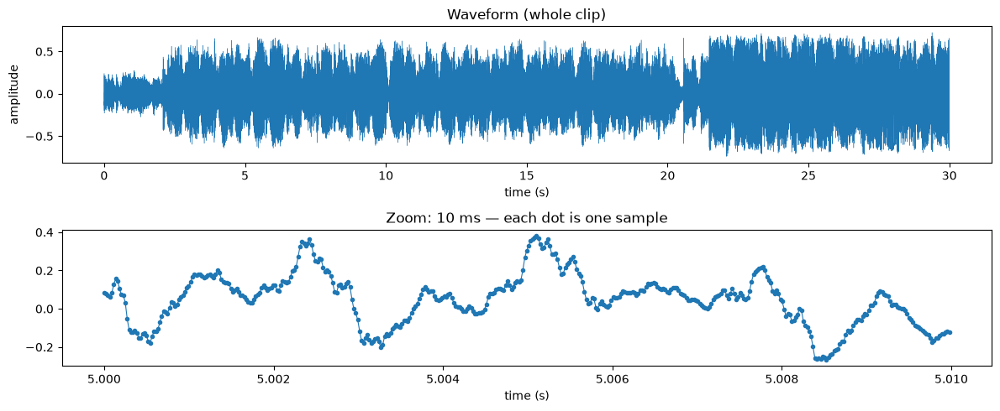

In [16]:
mono = y.mean(axis=0)
t = np.arange(len(mono)) / sr

fig, axes = plt.subplots(2, 1, figsize=(12, 5))
axes[0].plot(t, mono, linewidth=0.3)
axes[0].set(title="Waveform (whole clip)", xlabel="time (s)", ylabel="amplitude")

# Zoom into 10 ms: now you can see individual samples.
start, n = sr * 5, int(sr * 0.01)
axes[1].plot(t[start:start + n], mono[start:start + n], marker=".", linewidth=0.8)
axes[1].set(title="Zoom: 10 ms — each dot is one sample", xlabel="time (s)")
plt.tight_layout()

## 2. From time to frequency: FFT → STFT → spectrogram

The waveform tells you *how loud* things are over time but hides *which notes / instruments*
are playing. The **Fourier transform** decomposes a chunk of signal into sine waves of
different frequencies.

Music changes over time, so we apply the FFT to short overlapping windows: the
**Short-Time Fourier Transform (STFT)**.

- `n_fft`: window length. Bigger means sharper frequency resolution but blurrier timing.
- `hop_length`: step between windows.
- Result: a complex matrix `(freq_bins, frames)`. Its **magnitude** is the spectrogram,
  and its **phase** is needed to turn it back into audio.

Most source separation models (Spleeter, Open-Unmix) work on this magnitude spectrogram.

Text(0, 0.5, 'dB')

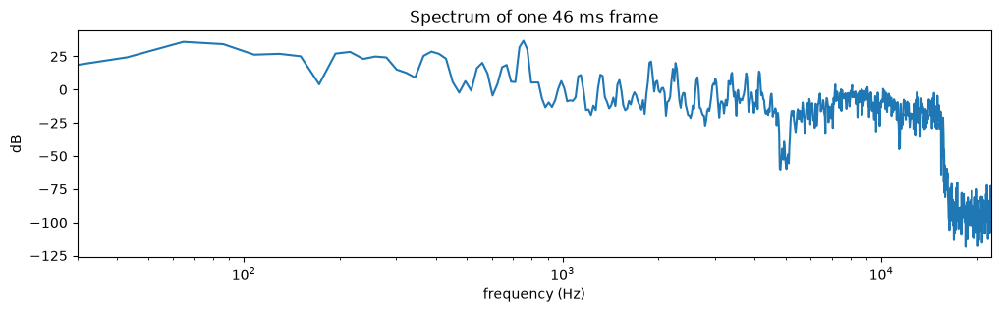

In [17]:
# FFT of a single 2048-sample frame (~46 ms)
frame = mono[sr * 5 : sr * 5 + 2048] * np.hanning(2048)
spectrum = np.abs(np.fft.rfft(frame))
freqs = np.fft.rfftfreq(2048, d=1 / sr)

plt.figure(figsize=(12, 3))
plt.plot(freqs, 20 * np.log10(spectrum + 1e-9))
plt.xscale("log"); plt.xlim(30, sr / 2)
plt.title("Spectrum of one 46 ms frame"); plt.xlabel("frequency (Hz)"); plt.ylabel("dB")

STFT shape (freq_bins, frames): (4097, 2584) | dtype: complex64


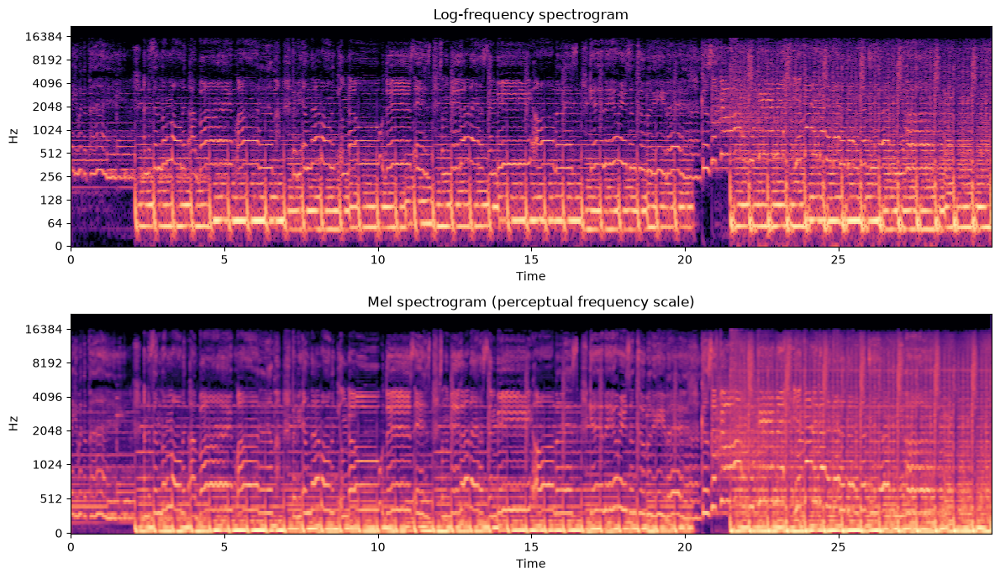

In [25]:
N_FFT, HOP = 8192, 512
S = librosa.stft(mono, n_fft=N_FFT, hop_length=HOP)
print("STFT shape (freq_bins, frames):", S.shape, "| dtype:", S.dtype)

S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)
mel = librosa.feature.melspectrogram(y=mono, sr=sr, n_fft=N_FFT, hop_length=HOP, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_axis="time", y_axis="log", ax=axes[0])
axes[0].set(title="Log-frequency spectrogram")
librosa.display.specshow(mel_db, sr=sr, hop_length=HOP, x_axis="time", y_axis="mel", ax=axes[1])
axes[1].set(title="Mel spectrogram (perceptual frequency scale)")
plt.tight_layout()

## 3. Separation without ML: masking

Look at the spectrogram. **Drums** show up as *vertical* lines (short, all frequencies),
while **sustained notes** (vocals, guitar, bass) show up as *horizontal* lines.

Harmonic/Percussive Source Separation (HPSS) uses this by median-filtering the spectrogram
horizontally and vertically. It builds a **soft mask** (values 0–1) per source, multiplies it
with the mixture STFT, then inverts back to audio.

This *mask × mixture spectrogram* idea is exactly what neural nets like Spleeter / Open-Unmix
learn to do, just much better. You'll build one yourself in Milestone 5.

Harmonic (sustained notes):


Percussive (drums/transients):


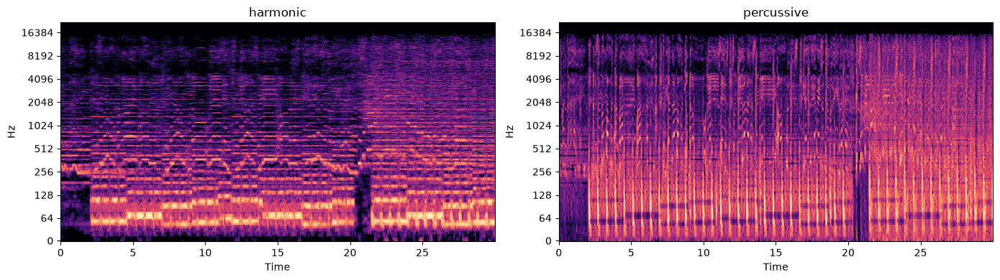

In [33]:
H, P = librosa.decompose.hpss(S, margin=1)
harmonic = librosa.istft(H, hop_length=HOP, length=len(mono))
percussive = librosa.istft(P, hop_length=HOP, length=len(mono))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, X, name in [(axes[0], H, "harmonic"), (axes[1], P, "percussive")]:
    librosa.display.specshow(librosa.amplitude_to_db(np.abs(X), ref=np.max(np.abs(S))),
                             sr=sr, hop_length=HOP, x_axis="time", y_axis="log", ax=ax)
    ax.set(title=name)
plt.tight_layout()

print("Harmonic (sustained notes):"); display(Audio(harmonic, rate=sr))
print("Percussive (drums/transients):"); display(Audio(percussive, rate=sr))

## 4. Real stem separation with Demucs v4

**Demucs** (Meta AI) is a deep network trained on thousands of songs with known stems.
Unlike Open-Unmix, it works on the **raw waveform and the spectrogram together**
("Hybrid Transformer Demucs"), so it doesn't have to guess the phase.

Models:
- `htdemucs`: 4 stems (drums, bass, other, vocals)
- `htdemucs_6s`: 6 stems (adds guitar, piano). The piano stem is weaker.
- `htdemucs_ft`: fine-tuned 4-stem model. Slightly better but 4× slower.

The first run downloads the weights (~80 MB).

In [43]:
from demucs.apply import apply_model
from demucs.pretrained import get_model

MODEL_NAME = "htdemucs_ft"
model = get_model(MODEL_NAME)
model.eval()
print("sources:", model.sources)
print("model sample rate:", model.samplerate, "| channels:", model.audio_channels)

Downloading: "https://dl.fbaipublicfiles.com/demucs/hybrid_transformer/f7e0c4bc-ba3fe64a.th" to /Users/gautamchaudhary/.cache/torch/hub/checkpoints/f7e0c4bc-ba3fe64a.th


100%|████████████████████████████████████████████████████████████████████| 80.2M/80.2M [00:08<00:00, 9.83MB/s]


Downloading: "https://dl.fbaipublicfiles.com/demucs/hybrid_transformer/d12395a8-e57c48e6.th" to /Users/gautamchaudhary/.cache/torch/hub/checkpoints/d12395a8-e57c48e6.th


100%|████████████████████████████████████████████████████████████████████| 80.2M/80.2M [00:08<00:00, 10.2MB/s]


Downloading: "https://dl.fbaipublicfiles.com/demucs/hybrid_transformer/92cfc3b6-ef3bcb9c.th" to /Users/gautamchaudhary/.cache/torch/hub/checkpoints/92cfc3b6-ef3bcb9c.th


100%|████████████████████████████████████████████████████████████████████| 80.2M/80.2M [00:08<00:00, 9.82MB/s]


Downloading: "https://dl.fbaipublicfiles.com/demucs/hybrid_transformer/04573f0d-f3cf25b2.th" to /Users/gautamchaudhary/.cache/torch/hub/checkpoints/04573f0d-f3cf25b2.th


100%|████████████████████████████████████████████████████████████████████| 80.2M/80.2M [00:09<00:00, 9.35MB/s]


sources: ['drums', 'bass', 'other', 'vocals']
model sample rate: 44100 | channels: 2


In [8]:
def load_for_model(path, model, offset=None, duration=None):
    """Load audio resampled to the model's rate, as a (channels, samples) float32 tensor."""
    wav, _ = librosa.load(path, sr=model.samplerate, mono=False, offset=offset or 0.0, duration=duration)
    if wav.ndim == 1:
        wav = np.stack([wav, wav])  # mono -> fake stereo
    return torch.from_numpy(wav[: model.audio_channels]).float()


def separate(wav, model, device=DEVICE):
    """Run Demucs on a (channels, samples) tensor. Returns {source: (channels, samples) array}."""
    # Same normalisation the demucs CLI uses
    ref = wav.mean(0)
    mean, std = ref.mean(), ref.std()
    x = (wav - mean) / std
    with torch.no_grad():
        try:
            out = apply_model(model, x[None], device=device, split=True, overlap=0.25, progress=True)[0]
        except RuntimeError as e:  # some ops may be unsupported on MPS
            print(f"{device} failed ({e}); falling back to CPU")
            out = apply_model(model, x[None], device="cpu", split=True, overlap=0.25, progress=True)[0]
    out = out * std + mean
    return {name: out[i].cpu().numpy() for i, name in enumerate(model.sources)}

In [9]:
import time

wav = load_for_model(SONG, model, OFFSET_S, DURATION_S)
t0 = time.time()
stems = separate(wav, model)
elapsed = time.time() - t0
print(f"separated {wav.shape[1] / model.samplerate:.1f}s of audio in {elapsed:.1f}s on {DEVICE}")

out_dir = STEMS_DIR / MODEL_NAME
out_dir.mkdir(parents=True, exist_ok=True)
for name, audio in stems.items():
    sf.write(out_dir / f"{name}.wav", audio.T, model.samplerate)
print("wrote stems to", out_dir)

100%|██████████████████████████████████████████████| 35.099999999999994/35.099999999999994 [00:05<00:00,  6.72seconds/s]


separated 30.0s of audio in 6.0s on mps
wrote stems to /Users/gautamchaudhary/Documents/Projects/music-studio/stems/htdemucs_6s


In [44]:
for name, audio in stems.items():
    print(name)
    display(Audio(audio, rate=model.samplerate))

drums


bass


other


vocals


guitar


piano


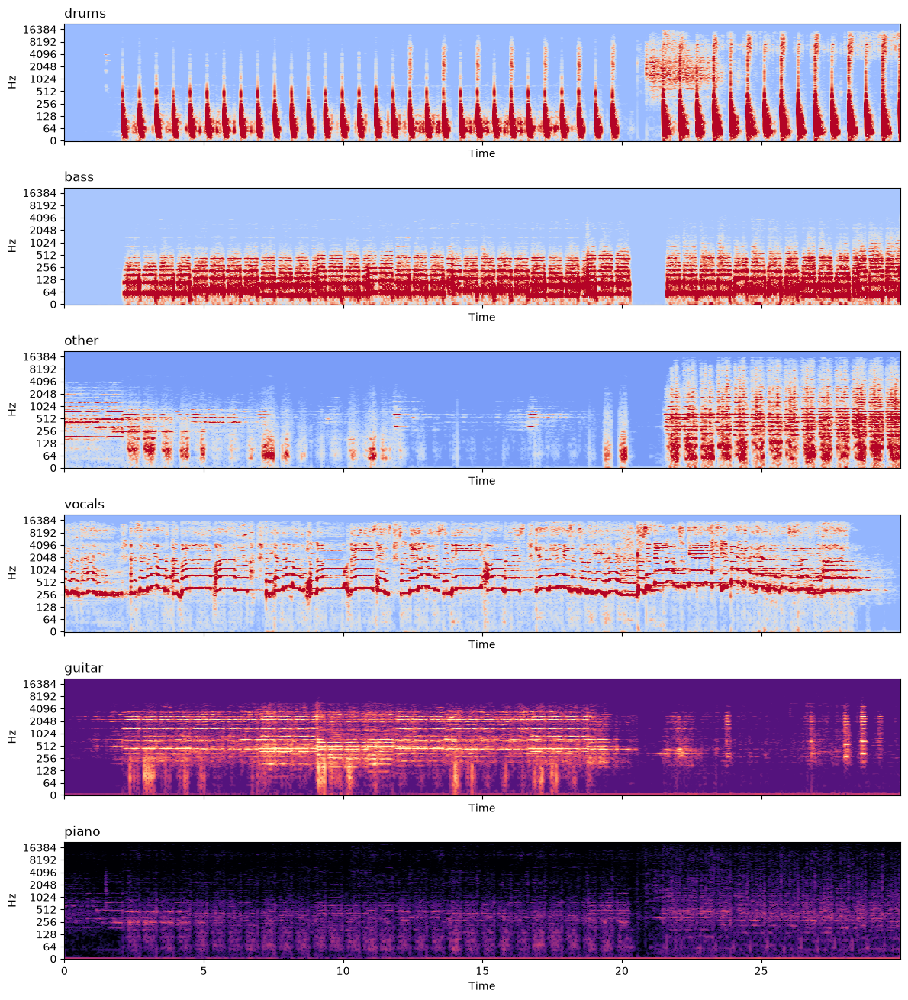

In [45]:
fig, axes = plt.subplots(len(stems), 1, figsize=(12, 2.2 * len(stems)), sharex=True)
for ax, (name, audio) in zip(axes, stems.items()):
    St = np.abs(librosa.stft(audio.mean(0), n_fft=N_FFT, hop_length=HOP))
    librosa.display.specshow(librosa.amplitude_to_db(St, ref=1.0, top_db=80), sr=model.samplerate,
                             hop_length=HOP, x_axis="time", y_axis="log", ax=ax, vmin=-60, vmax=20)
    ax.set_title(name, loc="left")
plt.tight_layout()

### Sanity check: do the stems add back up to the mix?

Demucs predicts each source independently, so the sum of stems should be *close* to the
mixture but not exact. The residual is a rough hint of what the model "lost".

In [46]:
mix = wav.numpy()
recon = sum(stems.values())
residual = mix - recon
snr = 10 * np.log10(np.sum(mix**2) / np.sum(residual**2))
print(f"mixture vs sum-of-stems SNR: {snr:.1f} dB (higher = closer)")
display(Audio(residual, rate=model.samplerate))

mixture vs sum-of-stems SNR: 23.0 dB (higher = closer)


## 5. (Optional) Measuring quality: SDR on MUSDB18

To compare models you need songs where the *true* stems are known. **MUSDB18** is the
standard benchmark (150 songs). The `musdb` package can download free **7-second
previews**, which is enough to learn the metric.

**SDR (Signal-to-Distortion Ratio)**, in dB, is higher = better:

$$\text{SDR} = 10 \log_{10} \frac{\sum s^2}{\sum (s - \hat{s})^2}$$

For reference, published full-MUSDB SDRs for HT-Demucs are about 9 dB averaged over stems.
MUSDB has 4 targets, so we use the 4-stem `htdemucs` here. Official benchmarks use the
`museval` package (BSSEval v4, computed per 1 s window). This simple global version is
fine for learning.

In [47]:
RUN_SDR = False  # set True to download the MUSDB18 previews and evaluate

def sdr(ref, est, eps=1e-9):
    return 10 * np.log10((np.sum(ref**2) + eps) / (np.sum((ref - est) ** 2) + eps))

if RUN_SDR:
    import musdb

    db = musdb.DB(root=str(ROOT / "data" / "musdb18-7s"), download=True, subsets="test")
    model4 = get_model("htdemucs")
    scores = {s: [] for s in model4.sources}
    for track in db.tracks[:5]:
        mix_t = torch.from_numpy(track.audio.T).float()  # (2, n) at 44.1 kHz
        est = separate(mix_t, model4)
        for s in model4.sources:
            scores[s].append(sdr(track.targets[s].audio.T, est[s]))
        print(track.name, {s: round(scores[s][-1], 2) for s in model4.sources})
    print("mean SDR (dB):", {s: round(float(np.mean(v)), 2) for s, v in scores.items()})

## Exercises

1. Change `N_FFT` to 512 and 8192. What happens to the spectrogram's time vs frequency sharpness?
2. Play with `margin` in `hpss`. When does it start sounding like Demucs? When does it break?
3. Compare `htdemucs`, `htdemucs_6s` and `htdemucs_ft` on the same clip, by ear and by speed.
4. Mute one stem (e.g. drop `vocals` from `sum(stems.values())`) to build a karaoke track. That's the core of the future mixer UI.
5. Read the [sigsep tutorial](https://sigsep.github.io/tutorials/) and the
   [HT-Demucs paper](https://arxiv.org/abs/2211.08553).

**Next (Milestone 2):** wrap `load_for_model` + `separate` into a FastAPI service with a background worker.